<a href="https://colab.research.google.com/github/Umarul-farooq/INTEL-WORKSHOP-OG/blob/main/DAY_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [78]:
df = pd.read_csv("/content/new_insurance_data.csv")

In [79]:
df.head()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


In [80]:
df.tail()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
1333,33.0,female,35.530,0.0,yes,63142.25346,32.0,1091267.0,170380500.5,2.0,3.101107e+09,northwest,55135.40209
1334,31.0,female,38.095,1.0,yes,43419.95227,31.0,1107872.0,201515184.8,2.0,3.484216e+09,northeast,58571.07448
1335,52.0,male,34.485,3.0,yes,52458.92353,25.0,1092005.0,223644981.3,2.0,3.640807e+09,northwest,60021.39897
1336,45.0,male,30.360,0.0,yes,69927.51664,34.0,1106821.0,252892382.6,3.0,4.006359e+09,southeast,62592.87309
1337,54.0,female,47.410,0.0,yes,63982.80926,31.0,1100328.0,261631699.3,3.0,4.117197e+09,southeast,63770.42801


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              1329 non-null   float64
 1   sex                              1338 non-null   object 
 2   bmi                              1335 non-null   float64
 3   children                         1333 non-null   float64
 4   smoker                           1338 non-null   object 
 5   Claim_Amount                     1324 non-null   float64
 6   past_consultations               1332 non-null   float64
 7   num_of_steps                     1335 non-null   float64
 8   Hospital_expenditure             1334 non-null   float64
 9   NUmber_of_past_hospitalizations  1336 non-null   float64
 10  Anual_Salary                     1332 non-null   float64
 11  region                           1338 non-null   object 
 12  charges             

In [82]:
df.describe()

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,charges
count,1329.000000,1335.000000,1333.000000,1324.000000,1332.000000,1.335000e+03,1.334000e+03,1336.000000,1.332000e+03,1338.000000
mean,39.310008,30.665112,1.090773,33361.327180,15.216216,9.100047e+05,1.584179e+07,1.060629,3.696849e+08,13270.422265
std,14.034818,6.101690,1.201856,15617.288337,7.467723,9.188612e+04,2.669305e+07,0.533583,5.668843e+08,12110.011237
min,18.000000,15.960000,0.000000,1920.136268,1.000000,6.954300e+05,2.945253e+04,0.000000,2.747072e+06,1121.873900
25%,27.000000,26.302500,0.000000,20768.860390,9.000000,8.471995e+05,4.077633e+06,1.000000,7.701932e+07,4740.287150
50%,39.000000,30.400000,1.000000,33700.310675,15.000000,9.143000e+05,7.490337e+06,1.000000,1.419361e+08,9382.033000
75%,51.000000,34.687500,2.000000,45052.331957,20.000000,9.716840e+05,1.084082e+07,1.000000,3.243499e+08,16639.912515
max,64.000000,53.130000,5.000000,77277.988480,40.000000,1.107872e+06,2.616317e+08,3.000000,4.117197e+09,63770.428010


In [83]:
df.columns = df.columns.str.lower()
df.head()

,age,sex,bmi,children,smoker,claim_amount,past_consultations,num_of_steps,hospital_expenditure,number_of_past_hospitalizations,anual_salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


In [84]:
df.rename(columns={'anual_salary': 'annual_salary'}, inplace=True)
df.head()

,age,sex,bmi,children,smoker,claim_amount,past_consultations,num_of_steps,hospital_expenditure,number_of_past_hospitalizations,annual_salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


In [85]:
df_cat = df.select_dtypes(include=['object'])
df_num = df.select_dtypes(include= np.number)

display("Categorical Feature:", df_cat)
display("Numerical Feature:", df_num)

'Categorical Feature:'

,sex,smoker,region
0,male,no,southeast
1,male,no,southeast
2,male,no,southeast
3,male,no,southeast
4,male,no,southeast
...,...,...,...
1333,female,yes,northwest
1334,female,yes,northeast
1335,male,yes,northwest
1336,male,yes,southeast


'Numerical Feature:'

,age,bmi,children,claim_amount,past_consultations,num_of_steps,hospital_expenditure,number_of_past_hospitalizations,annual_salary,charges
0,18.0,23.210,0.0,29087.54313,17.0,715428.0,4.720921e+06,0.0,5.578497e+07,1121.87390
1,18.0,30.140,0.0,39053.67437,7.0,699157.0,4.329832e+06,0.0,1.370089e+07,1131.50660
2,18.0,33.330,0.0,39023.62759,19.0,702341.0,6.884861e+06,0.0,7.352311e+07,1135.94070
3,18.0,33.660,0.0,28185.39332,11.0,700250.0,4.274774e+06,0.0,7.581968e+07,1136.39940
4,18.0,34.100,0.0,14697.85941,16.0,711584.0,3.787294e+06,0.0,2.301232e+07,1137.01100
...,...,...,...,...,...,...,...,...,...,...
1333,33.0,35.530,0.0,63142.25346,32.0,1091267.0,1.703805e+08,2.0,3.101107e+09,55135.40209
1334,31.0,38.095,1.0,43419.95227,31.0,1107872.0,2.015152e+08,2.0,3.484216e+09,58571.07448
1335,52.0,34.485,3.0,52458.92353,25.0,1092005.0,2.236450e+08,2.0,3.640807e+09,60021.39897
1336,45.0,30.360,0.0,69927.51664,34.0,1106821.0,2.528924e+08,3.0,4.006359e+09,62592.87309


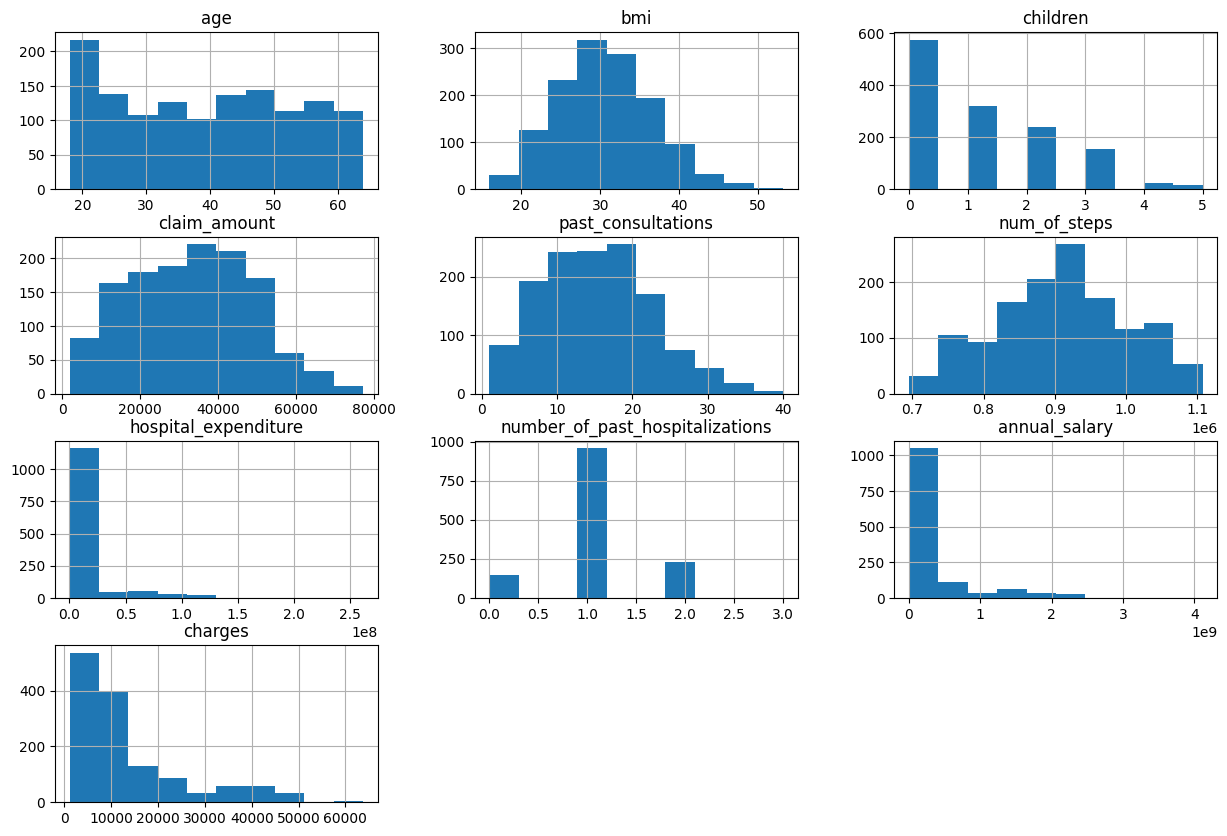

In [86]:
import matplotlib.pyplot as plt
df_num.hist(figsize=(15,10))
plt.tight_layout
plt.show()

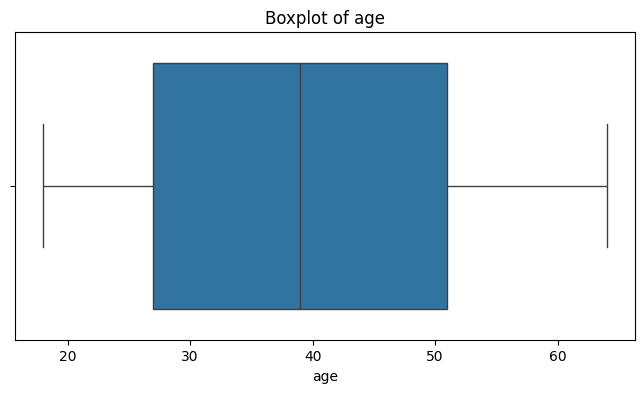

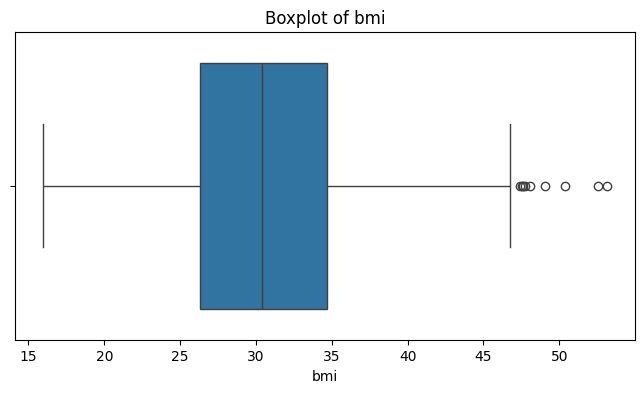

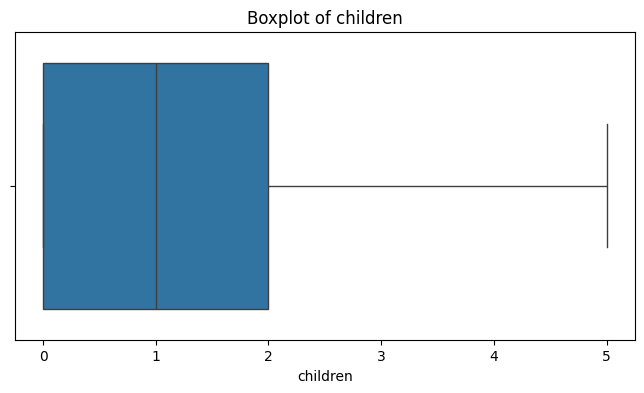

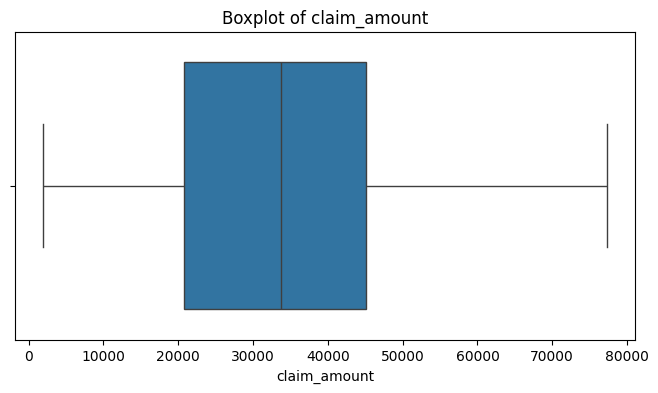

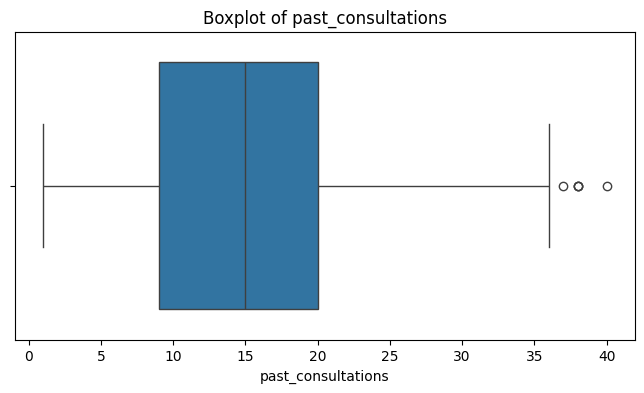

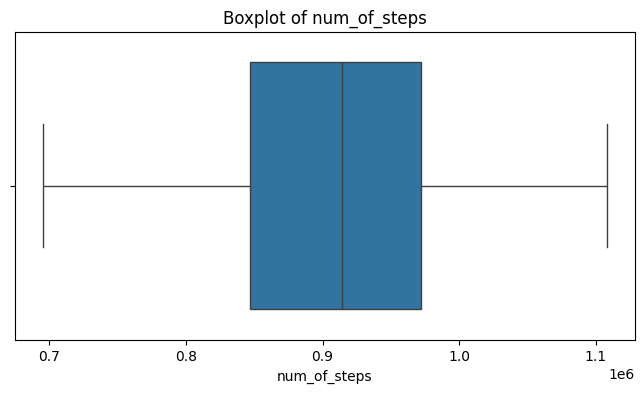

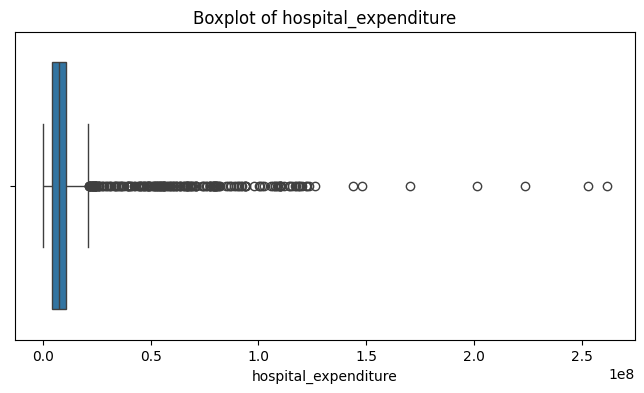

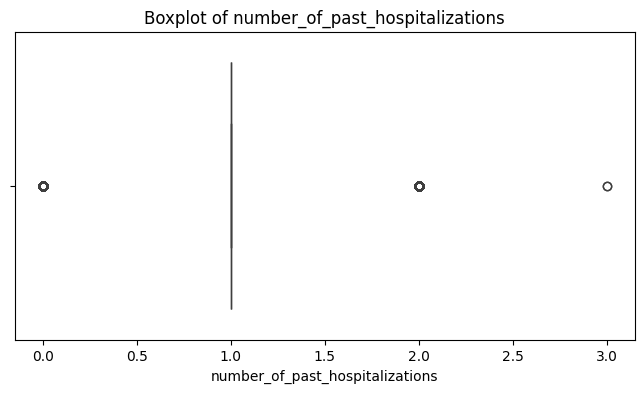

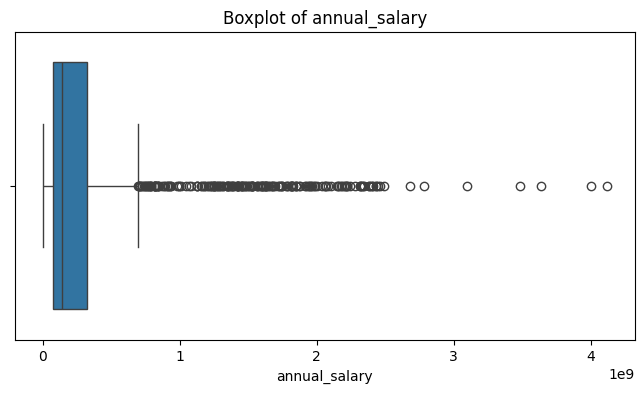

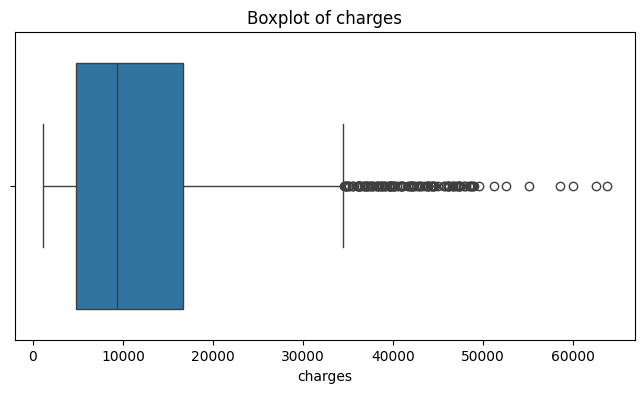

In [87]:
for col in df_num.columns:
  plt.figure(figsize= (8,4))
  sns.boxplot(x=df_num[col])
  plt.title(f'Boxplot of {col}')
  plt.show()

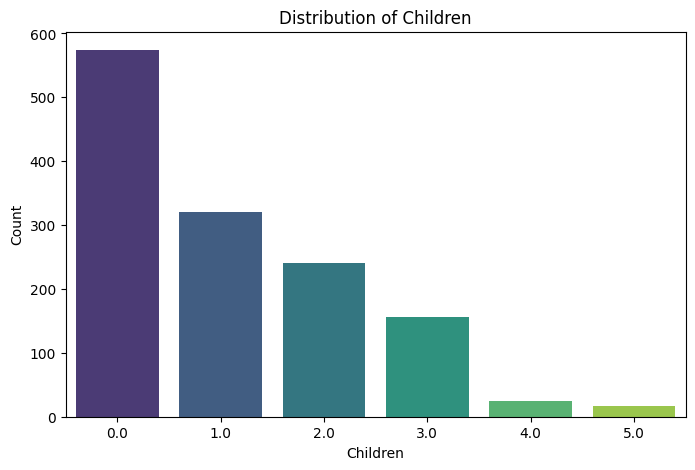

In [88]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.countplot(x='children', data = df, palette='viridis')
plt.xlabel('Children')
plt.ylabel('Count')
plt.title("Distribution of Children")
plt.show()

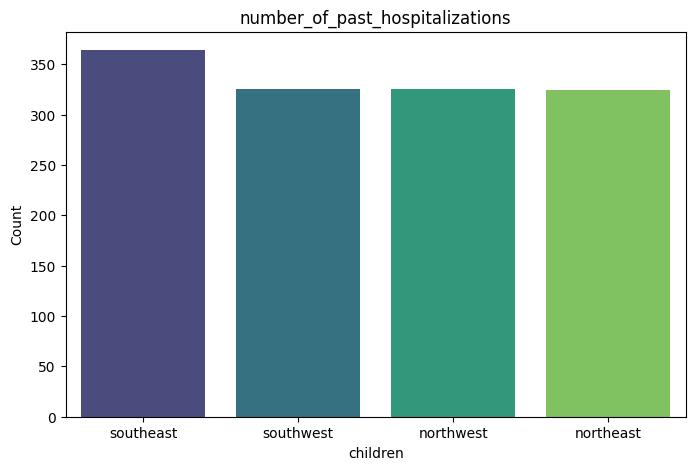

In [89]:
import seaborn as sns
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))
sns.countplot(x='region', data=df, palette='viridis')
plt.title('number_of_past_hospitalizations')
plt.xlabel('children')
plt.ylabel('Count')
plt.show()

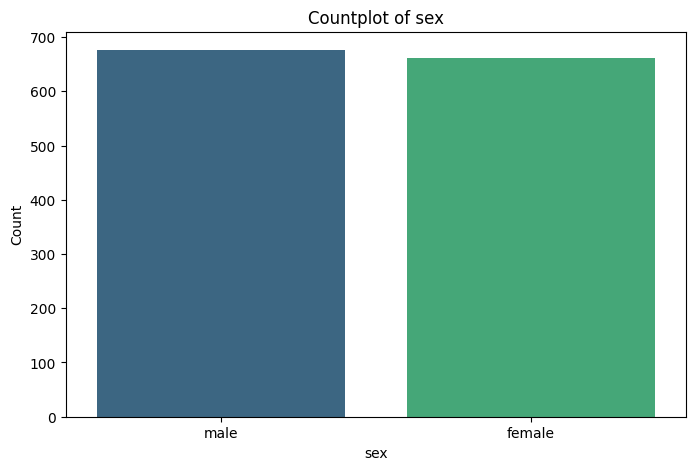

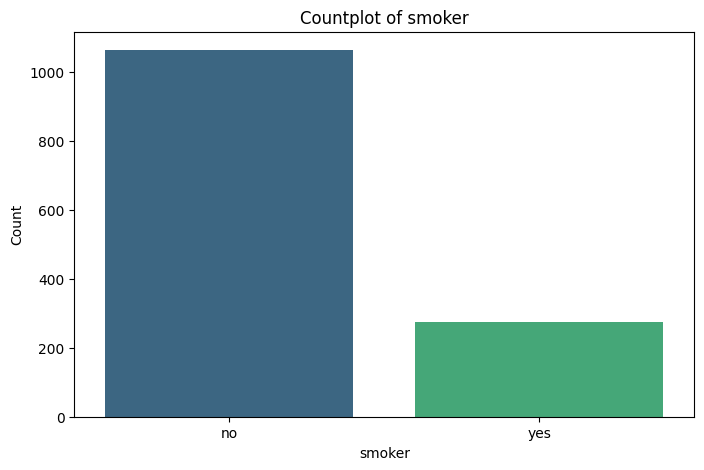

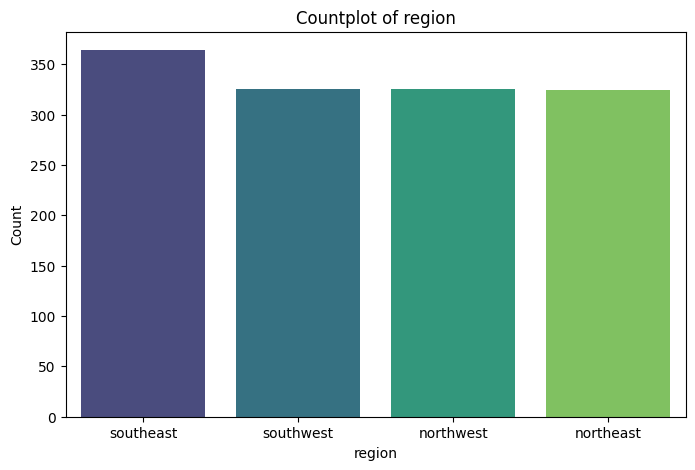

In [90]:
for col in df_cat.columns:
  plt.figure(figsize=(8,5))
  sns.countplot(x=col, data=df, palette='viridis')
  plt.title(f'Countplot of {col}')
  plt.xlabel(col)
  plt.ylabel('Count')
  plt.show()

In [91]:
df.isnull().sum()

,0
age,9
sex,0
bmi,3
children,5
smoker,0
claim_amount,14
past_consultations,6
num_of_steps,3
hospital_expenditure,4
number_of_past_hospitalizations,2


In [92]:
df['number_of_past_hospitalizations'].fillna(df['number_of_past_hospitalizations'].mode()[0], inplace=True)
df['children'].fillna(df['children'].mode()[0], inplace=True)

In [93]:
print(f"skewness")
for col in df_num.columns:
  skewness = df[col].skew()
  if skewness <= 0.5 or skewness >= 0.5:
    print(f"{col}: {skewness}")
    print("Use mean")
  else:
    print(f"{col}: {skewness:.4f}")
    print("Use median")

skewness
age: 0.04551443505897466
Use mean
bmi: 0.28388582142032676
Use mean
children: 0.9368975759232269
Use mean
claim_amount: 0.0982078802375097
Use mean
past_consultations: 0.4140463235671068
Use mean
num_of_steps: -0.0816904798062698
Use mean
hospital_expenditure: 3.7467801062030657
Use mean
number_of_past_hospitalizations: 0.11698037702591216
Use mean
annual_salary: 2.614587690281893
Use mean
charges: 1.5158796580240386
Use mean


In [94]:
for col in df_num.columns:
  skewness = df_num[col].skew()
  if skewness <= 0.5 or skewness >= 0.5:
    df_num[col].fillna(df_num[col].mean(), inplace=True)
  else:
    df_num[col].fillna(df_num[col].median(), inplace=True)

In [95]:
df_num.isnull().sum()

,0
age,0
bmi,0
children,0
claim_amount,0
past_consultations,0
num_of_steps,0
hospital_expenditure,0
number_of_past_hospitalizations,0
annual_salary,0
charges,0


In [96]:
df_cat.isnull().sum().sum()

np.int64(0)

In [97]:
df.duplicated().sum()

np.int64(0)

In [98]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = ['sex', 'smoker', 'region']
label_encoder = LabelEncoder()

for col in categorical_cols:
    df_cat[col] = label_encoder.fit_transform(df_cat[col])

display("Label Encoded Categorical Features:", df_cat)

'Label Encoded Categorical Features:'

,sex,smoker,region
0,1,0,2
1,1,0,2
2,1,0,2
3,1,0,2
4,1,0,2
...,...,...,...
1333,0,1,1
1334,0,1,0
1335,1,1,1
1336,1,1,2


In [99]:
df_cat = pd.concat([df_cat, df_num['children'],df_num['number_of_past_hospitalizations']], axis=1)

print("Shape of Combined_df_n_cat:", df_cat.shape)
display(df_cat.head())

Shape of Combined_df_n_cat: (1338, 5)


,sex,smoker,region,children,number_of_past_hospitalizations
0,1,0,2,0.0,0.0
1,1,0,2,0.0,0.0
2,1,0,2,0.0,0.0
3,1,0,2,0.0,0.0
4,1,0,2,0.0,0.0


In [100]:
df_num.head()

,age,bmi,children,claim_amount,past_consultations,num_of_steps,hospital_expenditure,number_of_past_hospitalizations,annual_salary,charges
0,18.0,23.21,0.0,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,1121.8739
1,18.0,30.14,0.0,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,1131.5066
2,18.0,33.33,0.0,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,1135.9407
3,18.0,33.66,0.0,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,1136.3994
4,18.0,34.10,0.0,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,1137.0110


In [101]:
df_num=df_num.drop('children', axis=1)
df_num=df_num.drop('number_of_past_hospitalizations', axis=1)

In [102]:
df_num.columns

Index(['age', 'bmi', 'claim_amount', 'past_consultations', 'num_of_steps',
       'hospital_expenditure', 'annual_salary', 'charges'],
      dtype='object')

In [103]:
df_num.shape

(1338, 8)

In [104]:
for col in ['bmi', 'past_consultations', 'hospital_expenditure', 'annual_salary']:
  Q1 = df_num[col].quantile(0.25)
  Q3 = df_num[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  df_num = df_num[(df_num[col] > lower_bound) & (df_num[col] < upper_bound)]

In [105]:
df_num.shape

(1030, 8)

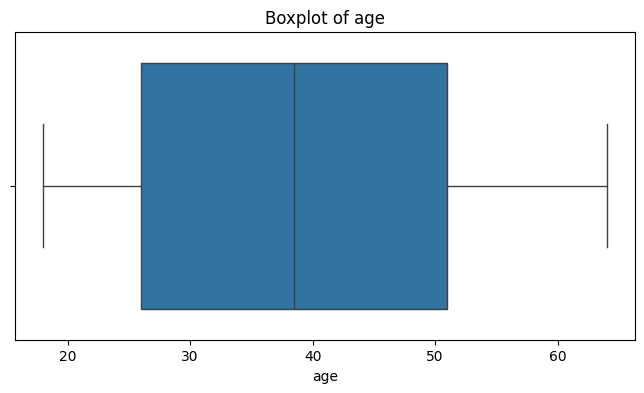

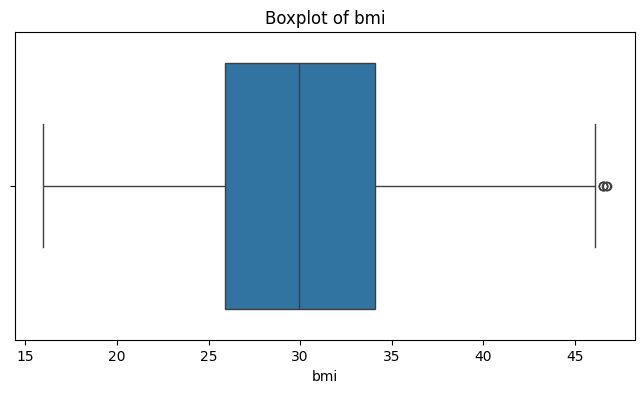

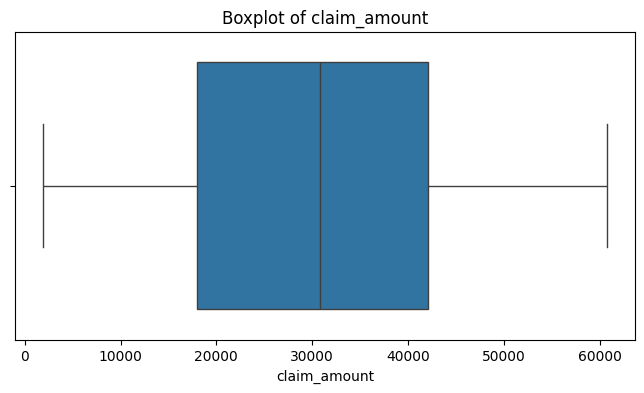

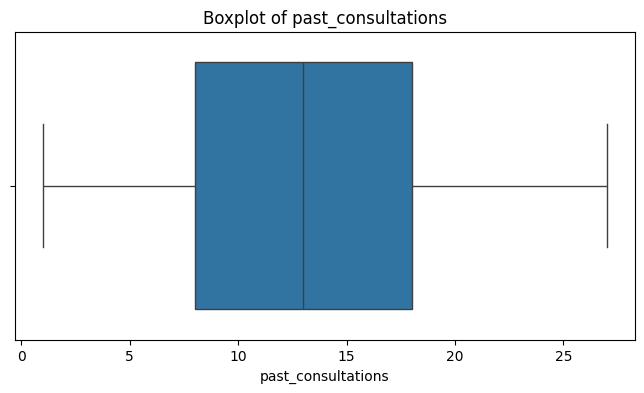

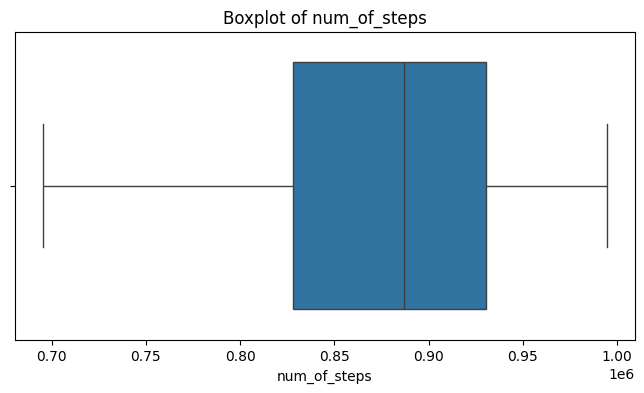

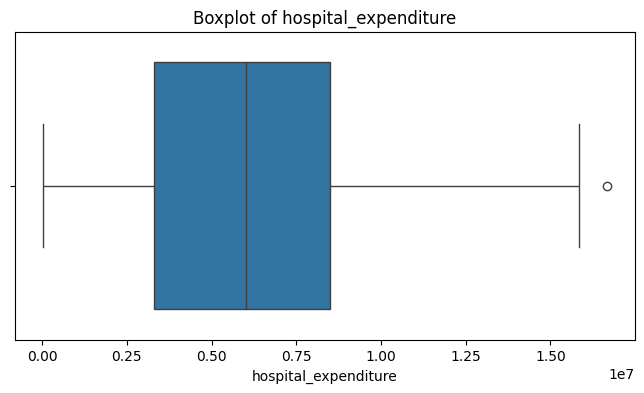

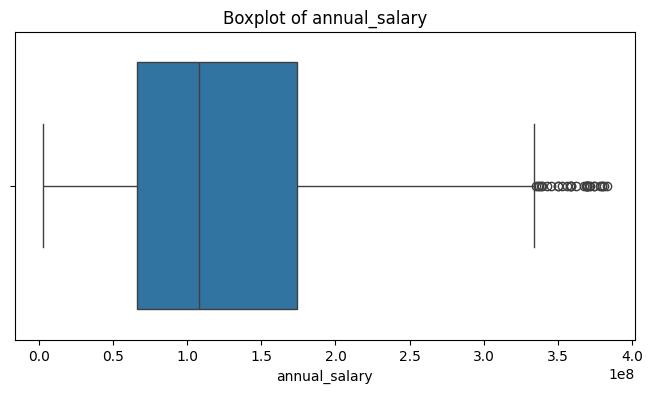

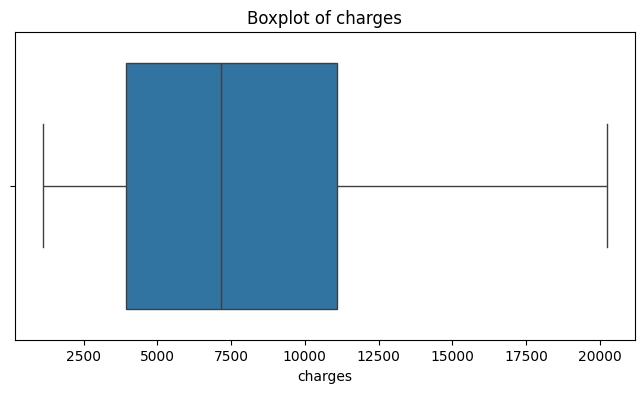

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in df_num.columns:
  plt.figure(figsize=(8,4))
  sns.boxplot(x=df_num[col])
  plt.title(f'Boxplot of {col}')
  plt.show

In [107]:
df_num.corr()

,age,bmi,claim_amount,past_consultations,num_of_steps,hospital_expenditure,annual_salary,charges
age,1.000000,0.155957,0.117750,0.172063,0.749468,0.160555,0.490802,0.676071
bmi,0.155957,1.000000,0.008343,0.023543,0.040324,0.013992,0.004105,0.010248
claim_amount,0.117750,0.008343,1.000000,0.071569,0.185434,0.054111,0.157826,0.192601
past_consultations,0.172063,0.023543,0.071569,1.000000,0.259401,0.088466,0.265710,0.278131
num_of_steps,0.749468,0.040324,0.185434,0.259401,1.000000,0.299554,0.767247,0.936946
hospital_expenditure,0.160555,0.013992,0.054111,0.088466,0.299554,1.000000,0.366809,0.358378
annual_salary,0.490802,0.004105,0.157826,0.265710,0.767247,0.366809,1.000000,0.892308
charges,0.676071,0.010248,0.192601,0.278131,0.936946,0.358378,0.892308,1.000000


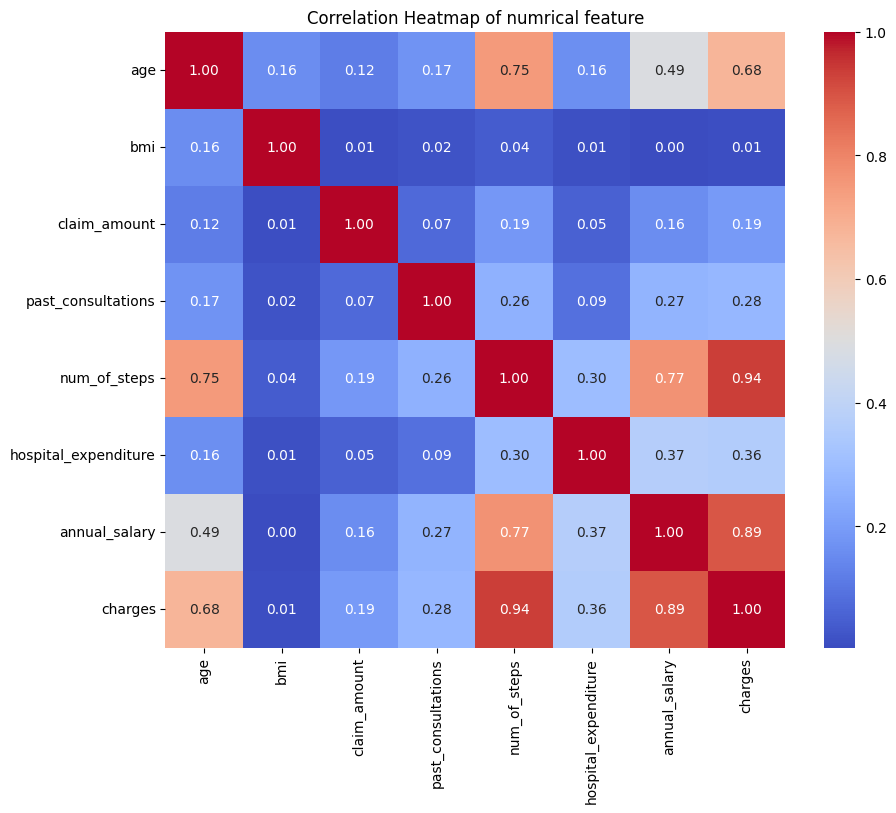

In [108]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))
sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of numrical feature')
plt.show()

In [109]:
df_num = df_num.drop("bmi", axis=1, errors='ignore')

In [110]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
x=df_num.drop("hospital_expenditure", axis=1)
vif_data = pd.DataFrame()
vif_data["feature"]= x.columns
vif_data["VIF"]=[variance_inflation_factor(x.values, i) for i in range(x.shape[1])]
vif_data

,feature,VIF
0,age,2.388203
1,claim_amount,1.041054
2,past_consultations,1.086596
3,num_of_steps,11.602582
4,annual_salary,6.270909
5,charges,20.587182


In [111]:
df_num = pd.concat([df_num, df_cat], axis=1)


display(df_num.head())


,age,claim_amount,past_consultations,num_of_steps,hospital_expenditure,annual_salary,charges,sex,smoker,region,children,number_of_past_hospitalizations
0,18.0,29087.54313,17.0,715428.0,4720920.992,55784970.05,1121.8739,1,0,2,0.0,0.0
1,18.0,39053.67437,7.0,699157.0,4329831.676,13700885.19,1131.5066,1,0,2,0.0,0.0
2,18.0,39023.62759,19.0,702341.0,6884860.774,73523107.27,1135.9407,1,0,2,0.0,0.0
3,18.0,28185.39332,11.0,700250.0,4274773.550,75819679.60,1136.3994,1,0,2,0.0,0.0
4,18.0,14697.85941,16.0,711584.0,3787293.921,23012320.01,1137.0110,1,0,2,0.0,0.0


In [114]:
x = df_num.drop("hospital_expenditure", axis=1)
y = df_num["hospital_expenditure"]
print("input target:", x.shape)
print("output target:", y.shape)

input target: (1338, 11)
output target: (1338,)


In [115]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("shape of x_train:", x_train.shape)
print("shape of x_test:", x_test.shape)
print("shape of y_train:", y_train.shape)
print("shape of y_test:", y_test.shape)

shape of x_train: (1070, 11)
shape of x_test: (268, 11)
shape of y_train: (1070,)
shape of y_test: (268,)


In [112]:
x = df_num.drop('charges', axis=1)
y = df_num['charges']

In [113]:
df_cat_aligned = df_cat.loc[x.index]